# Marriage and Divorce in America: What Has Changed, and Who Divorces?

**DATA 201 Capstone Project — Susana Rivera — Python Analytics Class, LaGuardia Community College — Fall 2026**

## Motivation

My motivation for this project is personal. My own marriage ended in divorce. Going through that made me ask questions I could not answer from my own experience alone. Is what happened to me common? Are fewer people getting married than a generation ago? Is divorce becoming more or less frequent? And do people who divorce tend to have things in common, like their age, education, income, or work situation?

I have also seen divorce from the professional side. In more than twenty years in payroll and HR, a change in marital status was never just a checkbox: it meant new tax withholding, insurance changes, and updated beneficiaries for real people going through a hard time. This project uses public government data to look at the bigger picture behind both of those experiences, with numbers instead of assumptions.

## Research questions

1. **How have the number of marriages and divorces changed over time** in the United States, and how does New York compare to other states?
2. **Were people more likely to divorce in 2019 than in other years?**
3. **What do people who are divorced have in common** compared with people who are married? I look at age, sex, education, income, and employment.

## Data sources

| Dataset | Source | What it contains | Size |
|---|---|---|---|
| National marriage & divorce rates, 2000–2017 | CDC / National Center for Health Statistics (NCHS), National Vital Statistics System | Number of marriages and divorces each year, U.S. population, and rate per 1,000 people | 18 rows × 4 columns per sheet |
| Marriage rates by state, 1990–2017 | CDC / NCHS | Marriage rate per 1,000 people for every state and DC | 51 rows × 21 year columns |
| Divorce rates by state, 1990–2017 | CDC / NCHS | Divorce rate per 1,000 people for every state and DC | 51 rows × 21 year columns |
| American Community Survey 2019, New York person records | U.S. Census Bureau, Public Use Microdata Sample (PUMS) | One row per surveyed person: marital status, whether they divorced in the past year, age, sex, education, income, employment, and a survey weight | 198,788 rows × 18 columns |

The CDC files come from https://ftp.cdc.gov/pub/health_Statistics/nchs/nvss/marriage-divorce/ .
The Census file comes from https://www2.census.gov/programs-surveys/acs/data/pums/2019/1-Year/csv_pny.zip . The original file has 288 columns; I kept the 18 columns I needed and saved them as a smaller CSV in the `data` folder so the notebook loads quickly.

## 1. Setting up

I import the three libraries I use throughout: **pandas** for working with tables, **matplotlib** for charts, and **numpy** for a few calculations. I also set a larger default font so every chart is easy to read.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 14, 'figure.figsize': (11, 6)})

# Show all columns when I print a table
pd.set_option('display.max_columns', 30)

## 2. Loading the CDC national data

The CDC spreadsheet is made for people to read, not for computers: it has a title at the top, footnotes at the bottom, and the marriage table and the divorce table are **stacked on the same sheet**, one under the other. So the first thing I do is look at the raw sheet exactly as pandas sees it, before I decide how to clean it.

In [2]:
national_file = 'data/national-marriage-divorce-rates-00-17.xlsx'

# See what sheets are inside the file
pd.ExcelFile(national_file).sheet_names

['Sheet1', 'Sheet2', 'Sheet3']

In [3]:
# Read the first sheet with no header so I can see the raw layout
raw = pd.read_excel(national_file, sheet_name=0, header=None)
raw

,0,1,2,3
0,Provisional number of marriages and marriage r...,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,Year,Marriages,Population,"Rate per 1,000 total population"
3,2017,2236496,325719178,6.9
4,2016,2251411,323127513,7
5,2015,2221579,321418820,6.9
6,2014 1,2140272,308759713,6.9
7,2013 1,2081301,306136672,6.8
8,2012,2131000,313914040,6.8
9,2011,2118000,311591917,6.8


## 3. Cleaning the CDC national data

Looking at the raw sheet above, I can see four problems to fix before I can analyze anything:

1. **Two tables in one sheet.** Marriages are in rows 3 to 20, and divorces are in rows 30 to 47. Everything else is titles, blank rows, and footnotes.
2. **Footnote numbers are stuck to some years**, like `2014 1` or `2017 1`. The CDC uses them to point to notes such as "Excludes data for Georgia."
3. **Every column is stored as text** (pandas calls it `object`), so I can't do math with it yet.
4. **The column names are long and inconsistent** ("Divorces & annulments", "Rate per 1,000 total population").

### Step 1: Cut out the two tables

`iloc` picks rows and columns by their position. I take the 18 rows of marriage data and the 18 rows of divorce data, and give each table short, clear column names.

In [4]:
marriages = raw.iloc[3:21].copy()
marriages.columns = ['year', 'marriages', 'marriage_population', 'marriage_rate']

divorces = raw.iloc[30:48].copy()
divorces.columns = ['year', 'divorces', 'divorce_population', 'divorce_rate']

marriages.head()

,year,marriages,marriage_population,marriage_rate
3,2017,2236496,325719178,6.9
4,2016,2251411,323127513,7
5,2015,2221579,321418820,6.9
6,2014 1,2140272,308759713,6.9
7,2013 1,2081301,306136672,6.8


In [5]:
# Before cleaning: every column is 'object', which means pandas is treating it as text
marriages.dtypes

year                   object
marriages              object
marriage_population    object
marriage_rate          object
dtype: object

### Step 2: Remove the footnote numbers from the years

Every year is four digits long, so I keep only the first four characters of each year and turn them into a whole number (`int`). That changes `2014 1` into `2014`.

In [6]:
marriages['year'] = marriages['year'].astype(str).str[:4].astype(int)
divorces['year'] = divorces['year'].astype(str).str[:4].astype(int)

divorces.head()

,year,divorces,divorce_population,divorce_rate
30,2017,787251,270423493,2.9
31,2016,776288,257904548,3.009982
32,2015,800909,258518265,3.1
33,2014,813862,256483624,3.2
34,2013,832157,254408815,3.3


### Step 3: Convert the other columns from text to numbers

`pd.to_numeric` turns text like `"2236496"` into the number 2236496 so I can add, compare, and chart it.

In [7]:
for col in ['marriages', 'marriage_population', 'marriage_rate']:
    marriages[col] = pd.to_numeric(marriages[col])

for col in ['divorces', 'divorce_population', 'divorce_rate']:
    divorces[col] = pd.to_numeric(divorces[col])

# After cleaning: the counts are whole numbers (int) and the rates are decimals (float)
marriages.dtypes

year                     int64
marriages                int64
marriage_population      int64
marriage_rate          float64
dtype: object

### Step 4: Combine the two tables into one

`merge` lines up the two tables by year, so each row has that year's marriages and divorces side by side. I sort from oldest to newest and round the rates to one decimal place.

**Important caveat:** the divorce population is smaller than the marriage population. That is because several states, including California, do not report divorces to the CDC. Because the counts cover different numbers of states, I compare **rates per 1,000 people**, not raw counts, when I put marriages and divorces side by side.

In [8]:
national = marriages.merge(divorces, on='year').sort_values('year').reset_index(drop=True)
national['marriage_rate'] = national['marriage_rate'].round(1)
national['divorce_rate'] = national['divorce_rate'].round(1)

national

,year,marriages,marriage_population,marriage_rate,divorces,divorce_population,divorce_rate
0,2000,2315000,281421906,8.2,944000,233550143,4.0
1,2001,2326000,284968955,8.2,940000,236416762,4.0
2,2002,2290000,287625193,8.0,955000,243108303,3.9
3,2003,2245000,290107933,7.7,927000,243902090,3.8
4,2004,2279000,292805298,7.8,879000,236402656,3.7
5,2005,2249000,295516599,7.6,847000,233495163,3.6
6,2006,2193000,294077247,7.5,872000,236094277,3.7
7,2007,2197000,301231207,7.3,856000,238352850,3.6
8,2008,2157000,304093966,7.1,844000,240545163,3.5
9,2009,2080000,306771529,6.8,840000,242610561,3.5


In [9]:
print(f'Rows: {national.shape[0]}   Columns: {national.shape[1]}')
print(f'Years covered: {national["year"].min()} to {national["year"].max()}')

Rows: 18   Columns: 7
Years covered: 2000 to 2017


## 4. How have marriages and divorces changed over time? (United States, 2000–2017)

This section answers the first part of research question 1. I use the **rates per 1,000 people**, not the raw counts, because the divorce numbers leave out states that do not report divorces (see the caveat in section 3).

### Step 1: Descriptive statistics

`describe()` gives a quick summary of each column: the average (`mean`), how spread out the values are (`std`), and the lowest and highest values (`min` and `max`).

In [10]:
national[['marriage_rate', 'divorce_rate']].describe().round(2)

,marriage_rate,divorce_rate
count,18.00,18.00
mean,7.28,3.52
std,0.51,0.32
min,6.80,2.90
25%,6.82,3.32
50%,7.05,3.60
75%,7.68,3.70
max,8.20,4.00


### Step 2: How much did each rate change from 2000 to 2017?

I compare the first year to the last year. The percent change tells me how big the drop was compared to where each rate started.

In [11]:
first = national.iloc[0]    # 2000
last = national.iloc[-1]    # 2017

change = pd.DataFrame({
    'rate_2000': [first['marriage_rate'], first['divorce_rate']],
    'rate_2017': [last['marriage_rate'], last['divorce_rate']],
}, index=['Marriage rate', 'Divorce rate'])

change['change'] = change['rate_2017'] - change['rate_2000']
change['percent_change'] = (change['change'] / change['rate_2000'] * 100).round(1)

change

,rate_2000,rate_2017,change,percent_change
Marriage rate,8.2,6.9,-1.3,-15.9
Divorce rate,4.0,2.9,-1.1,-27.5


### Step 3: Line chart of both rates over time

A line chart is the best way to show how something changes year by year. I use thick lines, dots for each year, and label the first and last values so the chart is easy to read. I also save it to the `charts` folder so I can put it in my presentation.

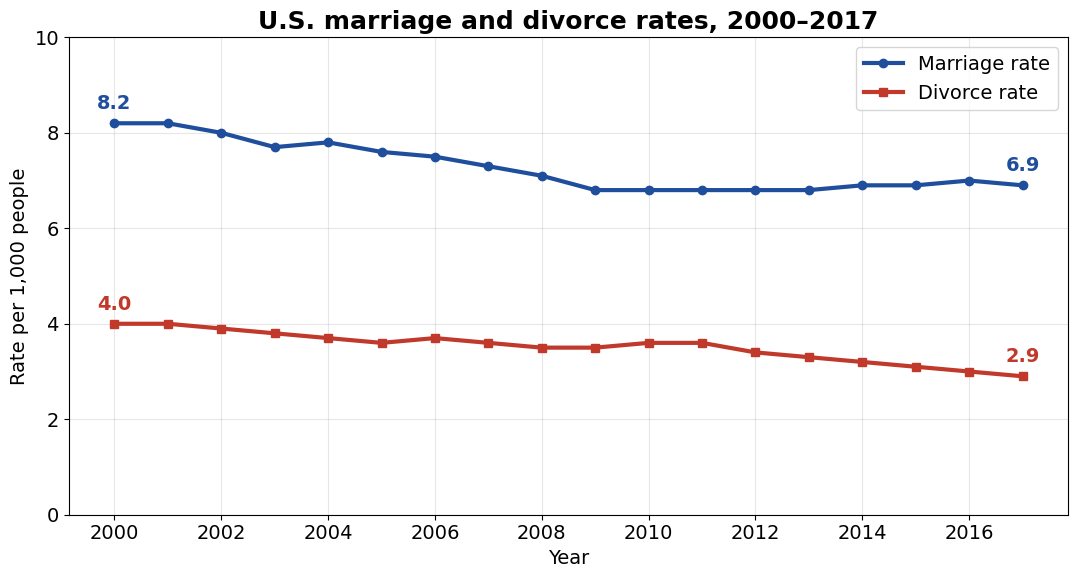

In [12]:
fig, ax = plt.subplots()

ax.plot(national['year'], national['marriage_rate'], marker='o', linewidth=3,
        color='#1f4e9c', label='Marriage rate')
ax.plot(national['year'], national['divorce_rate'], marker='s', linewidth=3,
        color='#c0392b', label='Divorce rate')

# Label the first and last value of each line
for col, color in [('marriage_rate', '#1f4e9c'), ('divorce_rate', '#c0392b')]:
    for row in [national.iloc[0], national.iloc[-1]]:
        ax.annotate(f"{row[col]:.1f}", (row['year'], row[col]),
                    textcoords='offset points', xytext=(0, 10),
                    ha='center', fontsize=14, fontweight='bold', color=color)

ax.set_title('U.S. marriage and divorce rates, 2000–2017', fontsize=18, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Rate per 1,000 people')
ax.set_ylim(0, 10)
ax.set_xticks(range(2000, 2018, 2))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig('charts/national_rates_2000_2017.png', dpi=150)
plt.show()

### Step 4: Is the drop a real trend or just random ups and downs? (inferential statistics)

A **linear regression** draws the straight line that best fits the points. It gives me two useful numbers:

- **slope**: how much the rate changes on average each year. A negative slope means the rate is going down.
- **p-value**: how likely it is to see a trend this strong if the rate were really not changing at all. A p-value **below 0.05** means the trend is **statistically significant**, so it is very unlikely to be just chance.

In [13]:
from scipy import stats

for col, name in [('marriage_rate', 'Marriage rate'), ('divorce_rate', 'Divorce rate')]:
    result = stats.linregress(national['year'], national[col])
    print(name)
    print(f'  Slope: {result.slope:.3f} per 1,000 people each year')
    if result.pvalue < 0.001:
        print('  p-value: less than 0.001')
    else:
        print(f'  p-value: {result.pvalue:.3f}')
    print(f'  Significant (p < 0.05)? {"Yes" if result.pvalue < 0.05 else "No"}')
    print()

Marriage rate
  Slope: -0.086 per 1,000 people each year
  p-value: less than 0.001
  Significant (p < 0.05)? Yes

Divorce rate
  Slope: -0.058 per 1,000 people each year
  p-value: less than 0.001
  Significant (p < 0.05)? Yes



### What I found

From 2000 to 2017, both marriage and divorce rates in the United States went down.

- **Fewer people got married.** The marriage rate dropped from 8.2 to 6.9 per 1,000 people, a drop of about 16%.
- **Fewer people got divorced.** The divorce rate dropped from 4.0 to 2.9 per 1,000 people, a drop of about 28%. Divorce fell faster than marriage.
- **These are real trends.** The regression test shows both drops are statistically significant (p-value less than 0.001), so they are not just random changes from year to year.

## 5. Loading and cleaning the CDC state data

To compare New York with other states, I use two more CDC files: marriage rates by state and divorce rates by state. Each one has a row for every state plus Washington, DC, and a column for each year: 1990, 1995, and every year from 1999 to 2017.

### Step 1: Load both files and look at the raw layout

In [14]:
state_marriage_raw = pd.read_excel('data/state-marriage-rates-90-95-99-17.xlsx', header=None)
state_divorce_raw = pd.read_excel('data/state-divorce-rates-90-95-99-17.xlsx', header=None)

print('Marriage file:', state_marriage_raw.shape)
print('Divorce file:', state_divorce_raw.shape)

state_marriage_raw.head(10)

Marriage file: (66, 22)
Divorce file: (65, 22)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
0,"Marriage rates by State: 1990, 1995, and 1999-...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,[Rates are based on provisional counts of marr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,State,Marriage rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,2017,2016.000000,2015.000000,2014,2013,2012.0,2011.0,2010.0,2009.0,2008.0,2007.0,2006,2005.0,2004.0,2003,2002,2001,2000,1999.0,1995.0,1990.0
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Alabama,7.04734,7.147821,7.351544,7.806776,7.817785,8.2,8.4,8.2,8.3,8.6,8.9,9.2,9.2,9.4,9.6,9.9,9.4,10.1,10.8,9.8,10.6
8,Alaska,6.914078,7.103441,7.407588,7.508836,7.293928,7.2,7.8,8.0,7.8,8.4,8.5,8.2,8.2,8.5,8.1,8.3,8.1,8.9,8.6,9.0,10.2
9,Arizona,5.834867,5.930541,5.922469,5.780449,5.401091,5.6,5.7,5.9,5.6,6.0,6.4,6.5,6.6,6.7,6.5,6.7,7.6,7.5,8.2,8.8,10.0


Looking at the raw files, I can see five problems to fix:

1. **Titles and footnotes.** The state data is only in rows 7 to 57. Everything above and below is titles, blank rows, and notes.
2. **The years are in row 5**, not in the column names, and some are stored as decimals, like `2016.0`.
3. **Footnote numbers are stuck to some state names**, like `California 1`.
4. **`---` means "data not available."** Pandas reads it as text, so I need to turn it into a proper missing value.
5. **The data is "wide":** one column per year. For charts and comparisons it is easier to have it "long": one row per state per year.

### Step 2: Cut out the state rows and use the years as column names

I take the years from row 5 and turn them into whole numbers, then keep only the 51 rows of state data.

In [15]:
marriage_years = state_marriage_raw.iloc[5, 1:].astype(int).tolist()
state_marriage = state_marriage_raw.iloc[7:58].copy()
state_marriage.columns = ['state'] + marriage_years

divorce_years = state_divorce_raw.iloc[5, 1:].astype(int).tolist()
state_divorce = state_divorce_raw.iloc[7:58].copy()
state_divorce.columns = ['state'] + divorce_years

print('Marriage table:', state_marriage.shape)
print('Divorce table:', state_divorce.shape)

state_marriage.head()

Marriage table: (51, 22)
Divorce table: (51, 22)


,state,2017,2016,2015,2014,2013,2012,2011,2010,2009,2008,2007,2006,2005,2004,2003,2002,2001,2000,1999,1995,1990
7,Alabama,7.04734,7.147821,7.351544,7.806776,7.817785,8.2,8.4,8.2,8.3,8.6,8.9,9.2,9.2,9.4,9.6,9.9,9.4,10.1,10.8,9.8,10.6
8,Alaska,6.914078,7.103441,7.407588,7.508836,7.293928,7.2,7.8,8.0,7.8,8.4,8.5,8.2,8.2,8.5,8.1,8.3,8.1,8.9,8.6,9.0,10.2
9,Arizona,5.834867,5.930541,5.922469,5.780449,5.401091,5.6,5.7,5.9,5.6,6.0,6.4,6.5,6.6,6.7,6.5,6.7,7.6,7.5,8.2,8.8,10.0
10,Arkansas,9.456845,9.860962,10.040279,10.112026,9.751052,10.9,10.4,10.8,10.7,10.6,12.0,12.4,12.9,13.4,13.4,14.3,14.3,15.4,14.8,14.4,15.3
11,California 1,6.27825,6.463590,6.184957,6.441492,6.460467,6.0,5.8,5.8,5.8,6.7,6.2,6.3,6.4,6.4,6.1,6.2,6.5,5.8,6.4,6.3,7.9


### Step 3: Remove the footnote numbers from the state names

`str.replace` with the pattern `\s*\d+$` finds any spaces and digits at the **end** of a name and removes them. That turns `California 1` into `California`.

In [16]:
print('Before:', state_marriage.loc[11, 'state'])

state_marriage['state'] = state_marriage['state'].str.replace(r'\s*\d+$', '', regex=True).str.strip()
state_divorce['state'] = state_divorce['state'].str.replace(r'\s*\d+$', '', regex=True).str.strip()

print('After: ', state_marriage.loc[11, 'state'])

Before: California 1
After:  California


### Step 4: Reshape from wide to long

`melt` turns the year columns into rows. Each state goes from one row with 21 year columns to 21 rows, one for each year. 51 states × 21 years = 1,071 rows.

In [17]:
marriage_long = state_marriage.melt(id_vars='state', var_name='year', value_name='marriage_rate')
divorce_long = state_divorce.melt(id_vars='state', var_name='year', value_name='divorce_rate')

print('Marriage long table:', marriage_long.shape)
print('Divorce long table:', divorce_long.shape)

marriage_long.head()

Marriage long table: (1071, 3)
Divorce long table: (1071, 3)


,state,year,marriage_rate
0,Alabama,2017,7.04734
1,Alaska,2017,6.914078
2,Arizona,2017,5.834867
3,Arkansas,2017,9.456845
4,California,2017,6.27825


### Step 5: Turn `---` into missing values and the rates into numbers

`pd.to_numeric` with `errors='coerce'` turns every number stored as text into a real number, and turns anything that is not a number (like `---`) into `NaN`, which is how pandas marks a missing value.

In [18]:
marriage_long['year'] = marriage_long['year'].astype(int)
divorce_long['year'] = divorce_long['year'].astype(int)

marriage_long['marriage_rate'] = pd.to_numeric(marriage_long['marriage_rate'], errors='coerce')
divorce_long['divorce_rate'] = pd.to_numeric(divorce_long['divorce_rate'], errors='coerce')

print('Missing marriage rates:', marriage_long['marriage_rate'].isna().sum())
print('Missing divorce rates: ', divorce_long['divorce_rate'].isna().sum())

Missing marriage rates: 7
Missing divorce rates:  104


Many more divorce rates are missing than marriage rates. Some states do not report divorces to the CDC at all. These states have **no divorce data for 2017**:

In [19]:
divorce_long[(divorce_long['year'] == 2017) & (divorce_long['divorce_rate'].isna())]['state'].tolist()

['California', 'Hawaii', 'Indiana', 'Minnesota', 'New Mexico']

### Step 6: Combine marriages and divorces into one table

I merge the two long tables on **state and year**, so each row has one state's marriage rate and divorce rate for one year. Then I round the rates to one decimal place and check New York's rows.

In [20]:
states = marriage_long.merge(divorce_long, on=['state', 'year'])
states = states.sort_values(['state', 'year']).reset_index(drop=True)
states['marriage_rate'] = states['marriage_rate'].round(1)
states['divorce_rate'] = states['divorce_rate'].round(1)

print(f'Rows: {states.shape[0]}   Columns: {states.shape[1]}')
print(f'States: {states["state"].nunique()}')

states[states['state'] == 'New York']

Rows: 1071   Columns: 4
States: 51


,state,year,marriage_rate,divorce_rate
672,New York,1990,8.6,3.2
673,New York,1995,8.0,3.0
674,New York,1999,7.3,3.3
675,New York,2000,7.1,3.0
676,New York,2001,7.6,3.5
677,New York,2002,7.3,3.4
678,New York,2003,6.8,3.2
679,New York,2004,6.8,3.0
680,New York,2005,6.8,2.9
681,New York,2006,6.9,3.1


## 6. How does New York compare to the rest of the country?

This section answers the second part of research question 1. I compare New York with the U.S. rates from section 4, year by year, and then see where New York ranks among all the states in 2017.

**Caveat:** the U.S. divorce rate leaves out states that do not report divorces (like California), while New York's rate is complete. So the comparison is close, but not perfect.

### Step 1: Put New York and the U.S. side by side

I take New York's rows from 2000 to 2017 and merge them with the national table by year. The `suffixes` option adds `_ny` or `_us` to the column names so I can tell them apart.

In [21]:
ny = states[(states['state'] == 'New York') & (states['year'] >= 2000)]

ny_vs_us = ny[['year', 'marriage_rate', 'divorce_rate']].merge(
    national[['year', 'marriage_rate', 'divorce_rate']],
    on='year', suffixes=('_ny', '_us'))

ny_vs_us

,year,marriage_rate_ny,divorce_rate_ny,marriage_rate_us,divorce_rate_us
0,2000,7.1,3.0,8.2,4.0
1,2001,7.6,3.5,8.2,4.0
2,2002,7.3,3.4,8.0,3.9
3,2003,6.8,3.2,7.7,3.8
4,2004,6.8,3.0,7.8,3.7
5,2005,6.8,2.9,7.6,3.6
6,2006,6.9,3.1,7.5,3.7
7,2007,6.8,2.9,7.3,3.6
8,2008,6.6,2.8,7.1,3.5
9,2009,6.5,2.6,6.8,3.5


### Step 2: Line charts of New York vs. the U.S.

I make one chart for marriage and one for divorce so each one is big and easy to read. The U.S. line uses the same color as in section 4, and New York is in green.

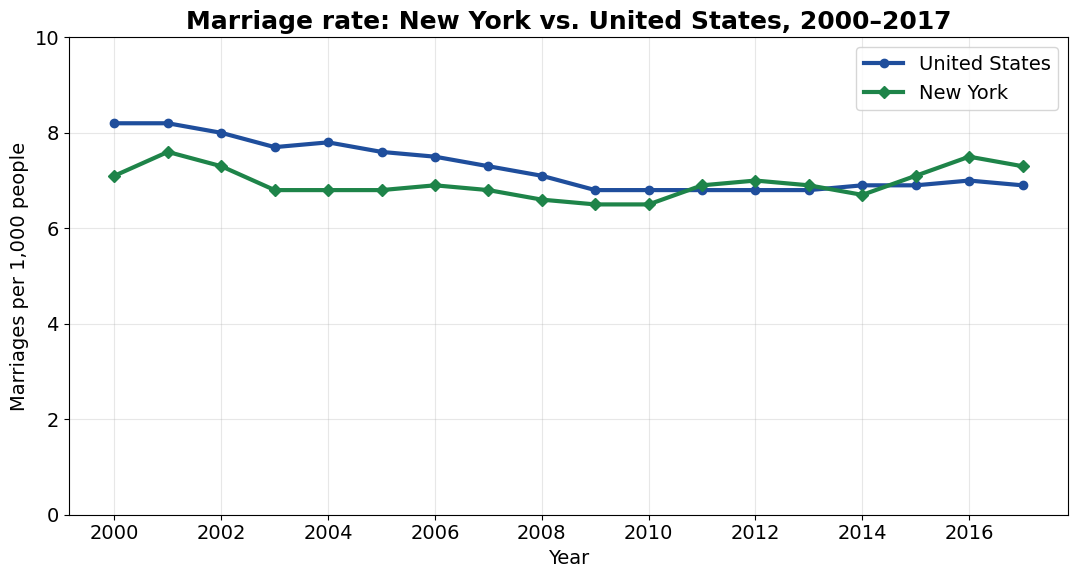

In [22]:
fig, ax = plt.subplots()
ax.plot(ny_vs_us['year'], ny_vs_us['marriage_rate_us'], marker='o', linewidth=3,
        color='#1f4e9c', label='United States')
ax.plot(ny_vs_us['year'], ny_vs_us['marriage_rate_ny'], marker='D', linewidth=3,
        color='#1e8449', label='New York')
ax.set_title('Marriage rate: New York vs. United States, 2000–2017', fontsize=18, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Marriages per 1,000 people')
ax.set_ylim(0, 10)
ax.set_xticks(range(2000, 2018, 2))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('charts/ny_vs_us_marriage.png', dpi=150)
plt.show()

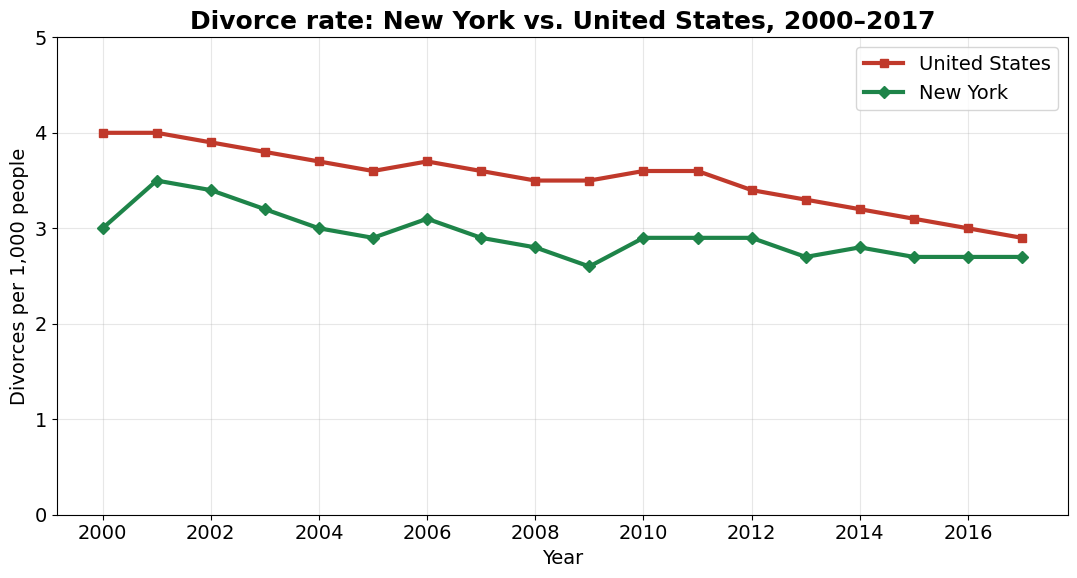

In [23]:
fig, ax = plt.subplots()
ax.plot(ny_vs_us['year'], ny_vs_us['divorce_rate_us'], marker='s', linewidth=3,
        color='#c0392b', label='United States')
ax.plot(ny_vs_us['year'], ny_vs_us['divorce_rate_ny'], marker='D', linewidth=3,
        color='#1e8449', label='New York')
ax.set_title('Divorce rate: New York vs. United States, 2000–2017', fontsize=18, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Divorces per 1,000 people')
ax.set_ylim(0, 5)
ax.set_xticks(range(2000, 2018, 2))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('charts/ny_vs_us_divorce.png', dpi=150)
plt.show()

### Step 3: Where does New York rank among the states in 2017?

`rank` numbers the states from highest rate (1) to lowest. I leave out states with missing data, so the divorce ranking has fewer states. I also show the **median**, the middle state, which is a fairer "typical state" than the average because Nevada's marriage rate (28.6, from all the Las Vegas weddings) would pull the average way up.

In [24]:
states_2017 = states[states['year'] == 2017]

for col, name in [('marriage_rate', 'Marriage rate'), ('divorce_rate', 'Divorce rate')]:
    ranked = states_2017.dropna(subset=[col]).copy()
    ranked['rank'] = ranked[col].rank(ascending=False, method='min').astype(int)
    ny_row = ranked[ranked['state'] == 'New York'].iloc[0]
    print(name)
    print(f'  New York: {ny_row[col]}   (rank {ny_row["rank"]} of {len(ranked)} states)')
    print(f'  Median state: {ranked[col].median()}')
    print()

Marriage rate
  New York: 7.3   (rank 12 of 51 states)
  Median state: 6.8

Divorce rate
  New York: 2.7   (rank 32 of 46 states)
  Median state: 3.0



### Step 4: Bar chart of divorce rates by state in 2017

This chart shows every state that reported divorces in 2017, from highest to lowest. New York is highlighted in green, and the dashed line marks the median state.

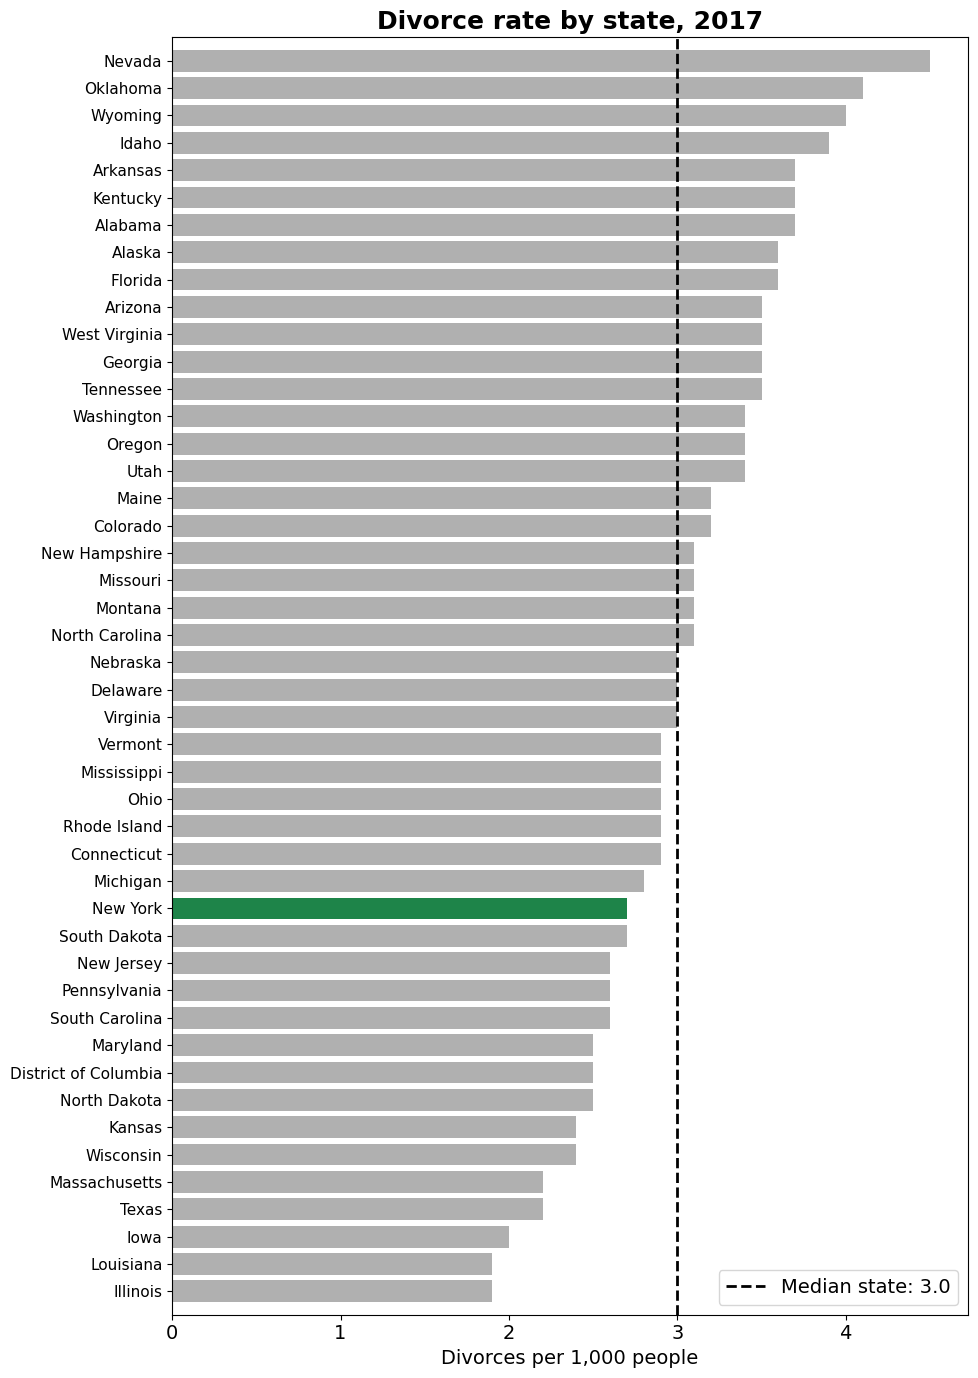

In [25]:
divorce_2017 = states_2017.dropna(subset=['divorce_rate']).sort_values('divorce_rate')
colors = ['#1e8449' if s == 'New York' else '#b0b0b0' for s in divorce_2017['state']]

fig, ax = plt.subplots(figsize=(10, 14))
ax.barh(divorce_2017['state'], divorce_2017['divorce_rate'], color=colors)
ax.axvline(divorce_2017['divorce_rate'].median(), color='black', linestyle='--', linewidth=2,
           label=f"Median state: {divorce_2017['divorce_rate'].median()}")
ax.set_title('Divorce rate by state, 2017', fontsize=18, fontweight='bold')
ax.set_xlabel('Divorces per 1,000 people')
ax.tick_params(axis='y', labelsize=11)
ax.margins(y=0.01)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('charts/divorce_by_state_2017.png', dpi=150)
plt.show()

### Step 5: Is New York's divorce rate really lower than the U.S. rate? (inferential statistics)

A **paired t-test** compares two sets of numbers that belong together in pairs. Here, each pair is the same year: New York's divorce rate and the U.S. divorce rate. The test checks whether the average difference between them is bigger than what random chance would produce. Like before, a p-value **below 0.05** means the difference is statistically significant.

In [26]:
difference = ny_vs_us['divorce_rate_ny'] - ny_vs_us['divorce_rate_us']
result = stats.ttest_rel(ny_vs_us['divorce_rate_ny'], ny_vs_us['divorce_rate_us'])

print(f'Years where New York was lower than the U.S.: {(difference < 0).sum()} of {len(difference)}')
print(f'Average difference: {difference.mean():.2f} divorces per 1,000 people')
if result.pvalue < 0.001:
    print('p-value: less than 0.001')
else:
    print(f'p-value: {result.pvalue:.3f}')
print(f'Significant (p < 0.05)? {"Yes" if result.pvalue < 0.05 else "No"}')

Years where New York was lower than the U.S.: 18 of 18
Average difference: -0.59 divorces per 1,000 people
p-value: less than 0.001
Significant (p < 0.05)? Yes


### What I found

- **New York has fewer divorces than the country as a whole.** New York's divorce rate was lower than the U.S. rate in every year from 2000 to 2017, by about 0.6 divorces per 1,000 people on average. The paired t-test shows this difference is statistically significant.
- **New York's marriage rate went from below average to above average.** In the early 2000s, New York had fewer marriages per person than the U.S. Starting in 2011, New York moved above the U.S. rate, and in 2017 it ranked 12th out of 51 states.
- **In 2017, New York was in the lower half of states for divorce**, ranked 32nd out of the 46 states that reported divorce data.

## 7. Was 2019 different, and who divorces? (New York, Census ACS 2019)

The CDC data stops at 2017, so for 2019 I switch to a different source: the **American Community Survey (ACS) 2019 1-year Public Use Microdata Sample** from the U.S. Census Bureau, for New York State. Instead of one number per state per year, this file has one row per **person**: 198,788 New Yorkers who answered the survey.

Each person has a weight (`PWGTP`) that says how many real New Yorkers that person represents. When I add up the weights I get the whole state population, so I use the weights whenever I count people.

The columns I kept:

| Column | Meaning |
|---|---|
| `AGEP` | Age |
| `SEX` | 1 = male, 2 = female |
| `MAR` | Marital status: 1 married, 2 widowed, 3 divorced, 4 separated, 5 never married |
| `MARHM` | Got married in the past 12 months (1 = yes, 2 = no) |
| `MARHD` | Got divorced in the past 12 months (1 = yes, 2 = no) |
| `MARHT` | How many times married (1, 2, 3 or more) |
| `SCHL` | Highest level of school finished (1 = none ... 21 = bachelor's, 22 = master's, 24 = doctorate) |
| `PINCP` | Personal income in the past 12 months |
| `PWGTP` | Person weight |

This section answers **research question 2** (was 2019 different?) and **research question 3** (what do divorced people have in common?).

### Step 1: Load the data and label the marital statuses

The `MAR` column is a code number, so I add a `status` column with words to make the tables readable.

In [27]:
acs = pd.read_csv('data/acs_2019_ny_persons.csv')

status_labels = {1: 'Married', 2: 'Widowed', 3: 'Divorced', 4: 'Separated', 5: 'Never married'}
acs['status'] = acs['MAR'].map(status_labels)

print(f'Rows (people): {acs.shape[0]:,}   Columns: {acs.shape[1]}')
print(f'New Yorkers represented (sum of weights): {acs["PWGTP"].sum():,}')
acs[['AGEP', 'SEX', 'MAR', 'status', 'MARHM', 'MARHD', 'MARHT', 'SCHL', 'PINCP', 'PWGTP']].head()

Rows (people): 198,788   Columns: 19
New Yorkers represented (sum of weights): 19,453,561


,AGEP,SEX,MAR,status,MARHM,MARHD,MARHT,SCHL,PINCP,PWGTP
0,18,1,5,Never married,NaN,NaN,NaN,19.0,190.0,23
1,33,1,5,Never married,NaN,NaN,NaN,16.0,7800.0,105
2,31,2,1,Married,2.0,2.0,1.0,13.0,4900.0,74
3,79,2,1,Married,2.0,2.0,2.0,19.0,54310.0,71
4,44,2,5,Never married,NaN,NaN,NaN,16.0,4000.0,21


### Step 2: Marital status of New York adults in 2019

I keep adults (18 and older) and use the weights to get the share of the adult population in each marital status.

In [28]:
adults = acs[acs['AGEP'] >= 18].copy()

status_share = (adults.groupby('status')['PWGTP'].sum() / adults['PWGTP'].sum() * 100).round(1)
status_share = status_share.reindex(['Married', 'Never married', 'Divorced', 'Widowed', 'Separated'])
status_share.name = 'percent_of_adults'

print(f'Adults represented: {adults["PWGTP"].sum():,}')
status_share.to_frame()

Adults represented: 15,435,896


,percent_of_adults
status,
Married,46.8
Never married,35.6
Divorced,9.3
Widowed,6.0
Separated,2.3


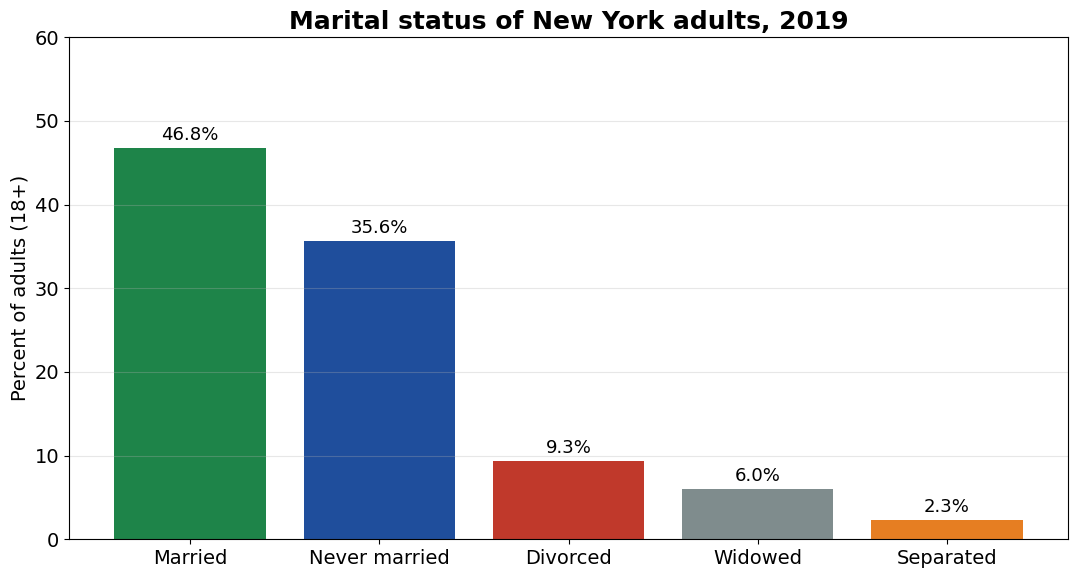

In [29]:
fig, ax = plt.subplots()
bars = ax.bar(status_share.index, status_share.values,
              color=['#1e8449', '#1f4e9c', '#c0392b', '#7f8c8d', '#e67e22'])
ax.bar_label(bars, labels=[f'{v}%' for v in status_share.values], fontsize=13, padding=3)
ax.set_title('Marital status of New York adults, 2019', fontsize=18, fontweight='bold')
ax.set_ylabel('Percent of adults (18+)')
ax.set_ylim(0, 60)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('charts/ny_2019_marital_status.png', dpi=150)
plt.show()

### Step 3: Was 2019 different? Marriages and divorces in the past 12 months (research question 2)

The ACS asks each person whether they got married (`MARHM`) or divorced (`MARHD`) in the past 12 months. I add up the weights of the people who said yes.

Two adjustments make this comparable to the CDC rates from sections 4 to 6:

1. **Two people per marriage.** Every marriage or divorce involves two people, so I divide the count of people by 2 to get the number of events.
2. **Per 1,000 people, all ages.** The CDC rates use the whole population as the denominator, so I do the same here.

In [30]:
total_pop = acs['PWGTP'].sum()

people_married = acs.loc[acs['MARHM'] == 1, 'PWGTP'].sum()
people_divorced = acs.loc[acs['MARHD'] == 1, 'PWGTP'].sum()

acs_marriage_rate = people_married / 2 / total_pop * 1000
acs_divorce_rate = people_divorced / 2 / total_pop * 1000

# New York's 2017 rates from the CDC state table (section 5)
ny_2017 = states[(states['state'] == 'New York') & (states['year'] == 2017)].iloc[0]

comparison = pd.DataFrame({
    'source': ['CDC (2017)', 'Census ACS (2019)'],
    'marriage_rate': [ny_2017['marriage_rate'], round(acs_marriage_rate, 1)],
    'divorce_rate': [ny_2017['divorce_rate'], round(acs_divorce_rate, 1)],
})

print(f'People who married in the past 12 months: {people_married:,}  ->  about {people_married // 2:,} marriages')
print(f'People who divorced in the past 12 months: {people_divorced:,}  ->  about {people_divorced // 2:,} divorces')
comparison

People who married in the past 12 months: 251,351  ->  about 125,675 marriages
People who divorced in the past 12 months: 89,397  ->  about 44,698 divorces


,source,marriage_rate,divorce_rate
0,CDC (2017),7.3,2.7
1,Census ACS (2019),6.5,2.3


### Step 4: Who is divorced? Divorced adults compared with married adults (research question 3)

To see what divorced people have in common, I compare two groups of adults: people who are **currently divorced** and people who are **currently married**. For each group I calculate the weighted average age, the share who are women, the average personal income, the share with a bachelor's degree or higher, and the share who have been married more than once.

In [31]:
def weighted_mean(values, weights):
    ok = values.notna()
    return np.average(values[ok], weights=weights[ok])

groups = {}
for name in ['Married', 'Divorced']:
    g = adults[adults['status'] == name]
    w = g['PWGTP']
    groups[name] = {
        'people': f"{w.sum():,}",
        'average_age': round(weighted_mean(g['AGEP'], w), 1),
        'percent_women': round(weighted_mean((g['SEX'] == 2).astype(float), w) * 100, 1),
        'average_income': round(weighted_mean(g['PINCP'], w)),
        'percent_bachelors_or_higher': round(weighted_mean((g['SCHL'] >= 21).astype(float), w) * 100, 1),
        'percent_married_more_than_once': round(weighted_mean((g['MARHT'] >= 2).astype(float), w) * 100, 1),
    }

profile = pd.DataFrame(groups)
profile

,Married,Divorced
people,"7,226,866","1,433,318"
average_age,52.5,57.5
percent_women,49.5,59.9
average_income,66792,52926
percent_bachelors_or_higher,41.4,31.0
percent_married_more_than_once,16.4,20.6


### Step 5: Divorce by age group

Young adults have had less time to marry and divorce, so instead of the whole population I look at **ever-married** adults (married, widowed, divorced, or separated) and ask: in each age group, what share is currently divorced?

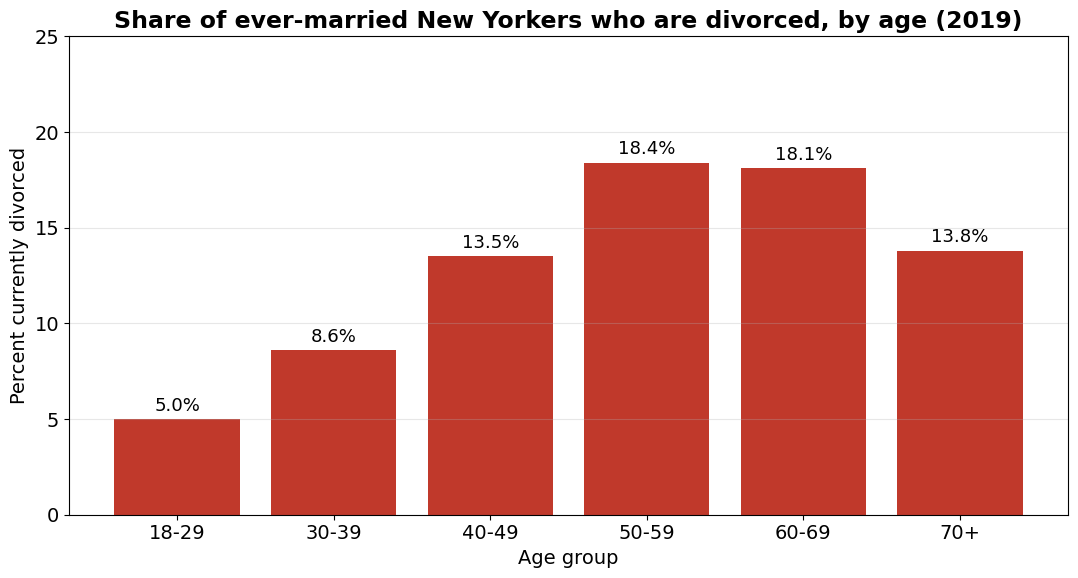

,percent_divorced
age_group,
18-29,5.0
30-39,8.6
40-49,13.5
50-59,18.4
60-69,18.1
70+,13.8


In [32]:
ever_married = adults[adults['MAR'].isin([1, 2, 3, 4])].copy()

age_bins = [18, 30, 40, 50, 60, 70, 200]
age_labels = ['18-29', '30-39', '40-49', '50-59', '60-69', '70+']
ever_married['age_group'] = pd.cut(ever_married['AGEP'], bins=age_bins, labels=age_labels, right=False)

def percent_divorced(group):
    return group.loc[group['status'] == 'Divorced', 'PWGTP'].sum() / group['PWGTP'].sum() * 100

divorced_by_age = ever_married.groupby('age_group', observed=True).apply(percent_divorced, include_groups=False).round(1)
divorced_by_age.name = 'percent_divorced'

fig, ax = plt.subplots()
bars = ax.bar(divorced_by_age.index.astype(str), divorced_by_age.values, color='#c0392b')
ax.bar_label(bars, labels=[f'{v}%' for v in divorced_by_age.values], fontsize=13, padding=3)
ax.set_title('Share of ever-married New Yorkers who are divorced, by age (2019)', fontsize=17, fontweight='bold')
ax.set_xlabel('Age group')
ax.set_ylabel('Percent currently divorced')
ax.set_ylim(0, 25)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('charts/ny_2019_divorced_by_age.png', dpi=150)
plt.show()

divorced_by_age.to_frame()

### Step 6: Divorce by education

I group the `SCHL` codes into four levels of education and ask the same question: among ever-married adults age 25 and older (old enough to have finished school), what share is currently divorced?

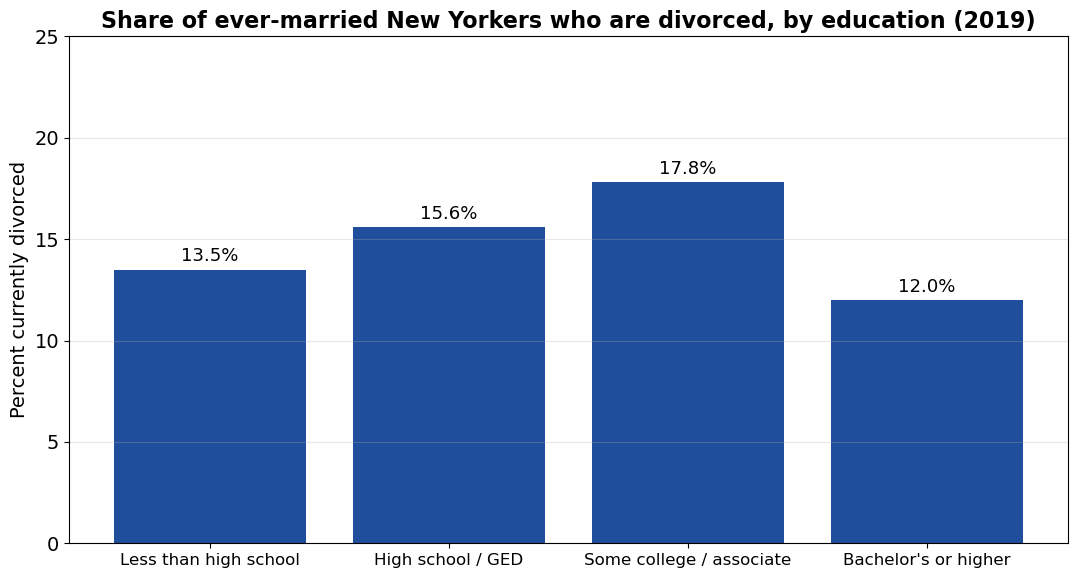

,percent_divorced
education,
Less than high school,13.5
High school / GED,15.6
Some college / associate,17.8
Bachelor's or higher,12.0


In [33]:
def education_level(schl):
    if pd.isna(schl):
        return None
    if schl < 16:
        return 'Less than high school'
    if schl <= 17:
        return 'High school / GED'
    if schl <= 20:
        return 'Some college / associate'
    return "Bachelor's or higher"

edu_order = ['Less than high school', 'High school / GED', 'Some college / associate', "Bachelor's or higher"]

ever_married_25 = ever_married[ever_married['AGEP'] >= 25].copy()
ever_married_25['education'] = ever_married_25['SCHL'].apply(education_level)

divorced_by_edu = (ever_married_25.groupby('education').apply(percent_divorced, include_groups=False)
                   .reindex(edu_order).round(1))
divorced_by_edu.name = 'percent_divorced'

fig, ax = plt.subplots()
bars = ax.bar(divorced_by_edu.index, divorced_by_edu.values, color='#1f4e9c')
ax.bar_label(bars, labels=[f'{v}%' for v in divorced_by_edu.values], fontsize=13, padding=3)
ax.set_title('Share of ever-married New Yorkers who are divorced, by education (2019)', fontsize=16, fontweight='bold')
ax.set_ylabel('Percent currently divorced')
ax.set_ylim(0, 25)
ax.grid(axis='y', alpha=0.3)
plt.xticks(fontsize=12)
plt.tight_layout()
plt.savefig('charts/ny_2019_divorced_by_education.png', dpi=150)
plt.show()

divorced_by_edu.to_frame()

### Step 7: Are these differences real? (inferential statistics)

Two tests:

- A **chi-square test of independence** checks whether two categories are related. Here: is education level related to being divorced instead of married? If the p-value is **below 0.05**, the pattern in the chart is not just random.
- A **two-sample t-test** (Welch's version, which does not assume equal spread) checks whether the average income of divorced adults is really different from married adults.

Both tests use the survey rows themselves (not the weights), which is the standard way to run them on a sample.

In [34]:
# Chi-square: education vs. divorced/married
two_groups = ever_married_25[ever_married_25['status'].isin(['Married', 'Divorced'])]
table = pd.crosstab(two_groups['education'], two_groups['status']).reindex(edu_order)
chi2, p_chi, dof, expected = stats.chi2_contingency(table)

print('Counts of survey respondents:')
print(table)
print()
print(f'Chi-square statistic: {chi2:,.1f}   degrees of freedom: {dof}')
print(f'p-value: {"less than 0.001" if p_chi < 0.001 else round(p_chi, 3)}')
print(f'Education and divorce are related (p < 0.05)? {"Yes" if p_chi < 0.05 else "No"}')
print()

# Welch t-test: income of divorced vs. married adults
income_married = adults.loc[(adults['status'] == 'Married') & adults['PINCP'].notna(), 'PINCP']
income_divorced = adults.loc[(adults['status'] == 'Divorced') & adults['PINCP'].notna(), 'PINCP']
t_result = stats.ttest_ind(income_divorced, income_married, equal_var=False)

print(f'Average income, married:  ${income_married.mean():,.0f}')
print(f'Average income, divorced: ${income_divorced.mean():,.0f}')
print(f'p-value: {"less than 0.001" if t_result.pvalue < 0.001 else round(t_result.pvalue, 3)}')
print(f'Income differs significantly (p < 0.05)? {"Yes" if t_result.pvalue < 0.05 else "No"}')

Counts of survey respondents:
status                    Divorced  Married
education                                  
Less than high school         1616     7667
High school / GED             4369    19237
Some college / associate      4577    19598
Bachelor's or higher          4666    33895

Chi-square statistic: 717.5   degrees of freedom: 3
p-value: less than 0.001
Education and divorce are related (p < 0.05)? Yes

Average income, married:  $66,830
Average income, divorced: $51,799
p-value: less than 0.001
Income differs significantly (p < 0.05)? Yes


### What I found

- **2019 was not a different year for New York.** The Census numbers for 2019 (6.5 marriages and 2.3 divorces per 1,000 people) are slightly lower than the CDC numbers for 2017 (7.3 and 2.7), which is exactly what the long, slow decline from sections 4 and 6 would predict. New York had about 125,700 marriages and 44,700 divorces in 2019, roughly 3 marriages for every divorce.
- **In 2019, fewer than half of New York adults were married** (46.8%). About 9.3% were divorced and 35.6% had never married.
- **Divorced New Yorkers are older, more often women, and earn less.** Compared with married adults, divorced adults average 5 years older (57.5 vs. 52.5), are 60% women (vs. 50%), earn about $14,000 less per year on average ($52,900 vs. $66,800), and are less likely to have a bachelor's degree (31% vs. 41%). One in five divorced adults has been married more than once.
- **Divorce peaks in the 50s and 60s.** Among ever-married adults, the share who are currently divorced climbs from 5% in the 18-29 group to about 18% in the 50-69 groups. It dips after 70, mostly because widowhood takes over at that age.
- **Education matters, but not in a straight line.** Adults with some college or an associate degree have the highest divorce share (17.8%), and adults with a bachelor's degree or higher have the lowest (12.0%). The chi-square test (p < 0.001) confirms that education and divorce are related, and the t-test (p < 0.001) confirms that the income gap between divorced and married adults is real, not random.

## 8. Conclusion

**Research question 1: How have marriages and divorces changed over time, and how does New York compare?**
Both rates fell in the United States from 2000 to 2017. The marriage rate dropped from 8.2 to 6.9 per 1,000 people, and the divorce rate dropped from 4.0 to 2.9, both statistically significant downward trends. New York followed the same downward path but with consistently fewer divorces than the country, in every one of the 18 years. By 2017 New York was above the U.S. average for marriage and in the lower half of states for divorce.

**Research question 2: Was 2019 different?**
No. Census data for 2019 puts New York at about 6.5 marriages and 2.3 divorces per 1,000 people, a small step down from the CDC's 2017 figures and right on the trend line. Nothing about 2019 stands out.

**Research question 3: What do divorced people have in common?**
In New York in 2019, divorced adults were older (most divorce shows up in the 50s and 60s), more likely to be women, earned about $14,000 less per year than married adults, and were less likely to hold a bachelor's degree. Adults with a bachelor's degree or higher had the lowest share currently divorced; adults with some college but no bachelor's had the highest. Both patterns were statistically significant.

**Limitations**
- The CDC national divorce rate leaves out states that do not report divorces (California, for example), so it is not a complete count.
- The CDC data ends in 2017 and the Census data covers only 2019, so the two sources measure slightly different things and I could not build one continuous line through 2019.
- The Census data shows who is divorced *right now*, not who *got* divorced. Someone who divorced and remarried counts as married.
- These are patterns, not causes. Being older or earning less does not cause divorce. A divorce can also cause lower income, especially for women.

**What I would do next**
Add the CDC data for 2018 through 2023 to see whether the pandemic years changed the trend, and use several years of Census data to follow the same age groups over time.

## 9. Data sources and references

1. National Center for Health Statistics (CDC). *National Marriage and Divorce Rate Trends, 2000-2017.* https://www.cdc.gov/nchs/nvss/marriage-divorce.htm
2. National Center for Health Statistics (CDC). *Marriage Rates by State, 1990, 1995, 1999-2017* and *Divorce Rates by State, 1990, 1995, 1999-2017.* https://www.cdc.gov/nchs/nvss/marriage-divorce.htm
3. U.S. Census Bureau. *American Community Survey 2019 1-Year Public Use Microdata Sample (PUMS), New York.* https://www.census.gov/programs-surveys/acs/microdata.html
4. U.S. Census Bureau. *2019 ACS PUMS Data Dictionary* (definitions of `MAR`, `MARHD`, `MARHM`, `MARHT`, `SCHL`, `PINCP`, `PWGTP`). https://www.census.gov/programs-surveys/acs/microdata/documentation.html
5. pandas, NumPy, Matplotlib, and SciPy documentation for the functions used in this notebook.